# Scaling and Normalization

Features on very different scales (square feet in thousands, number of bathrooms 1–4) confuse models that use distances or gradients. **Scaling** changes the range of a feature; **transformations** (log, power, quantile) change the shape of its distribution. Some models need them, others ignore them.

**After this lesson you can:**

1. Apply standard, min-max, robust and max-abs scaling and explain the differences.
2. Use log, Box-Cox / Yeo-Johnson and quantile transforms for skewed features.
3. Transform the target of a regression and back-transform predictions.
4. Measure which models need scaling (k-NN, linear models with regularisation) and which do not (trees).

**Data:** Ames Housing.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (FunctionTransformer, MaxAbsScaler, MinMaxScaler, PowerTransformer, QuantileTransformer,
                                   RobustScaler, StandardScaler)

ames = datasets.ames()
ames = ames[ames["Gr_Liv_Area"] <= 4000]                           # documented removal (Lesson 03)
features = ["Gr_Liv_Area", "Lot_Area", "Total_Bsmt_SF", "Garage_Area", "Year_Built", "Full_Bath", "TotRms_AbvGrd", "Fireplaces"]
X, y = ames[features], ames["Sale_Price"]
X.describe().loc[["mean", "std", "min", "max"]].round(1)

,Gr_Liv_Area,Lot_Area,Total_Bsmt_SF,Garage_Area,Year_Built,Full_Bath,TotRms_AbvGrd,Fireplaces
mean,1494.0,10103.6,1046.5,471.7,1971.3,1.6,6.4,0.6
std,486.3,7782.0,421.5,214.0,30.2,0.6,1.6,0.6
min,334.0,1300.0,0.0,0.0,1872.0,0.0,2.0,0.0
max,3820.0,215245.0,3206.0,1488.0,2010.0,4.0,14.0,4.0


## 1. Scalers

| Scaler | Formula | Use |
| :--- | :--- | :--- |
| `StandardScaler` | $(x - \mu) / \sigma$ | default for linear models, SVM, neural networks |
| `MinMaxScaler` | $(x - \min) / (\max - \min)$ | bounded inputs (images, some neural networks); sensitive to outliers |
| `RobustScaler` | $(x - \text{median}) / IQR$ | data with outliers |
| `MaxAbsScaler` | $x / \max\lvert x \rvert$ | sparse data (keeps zeros) |

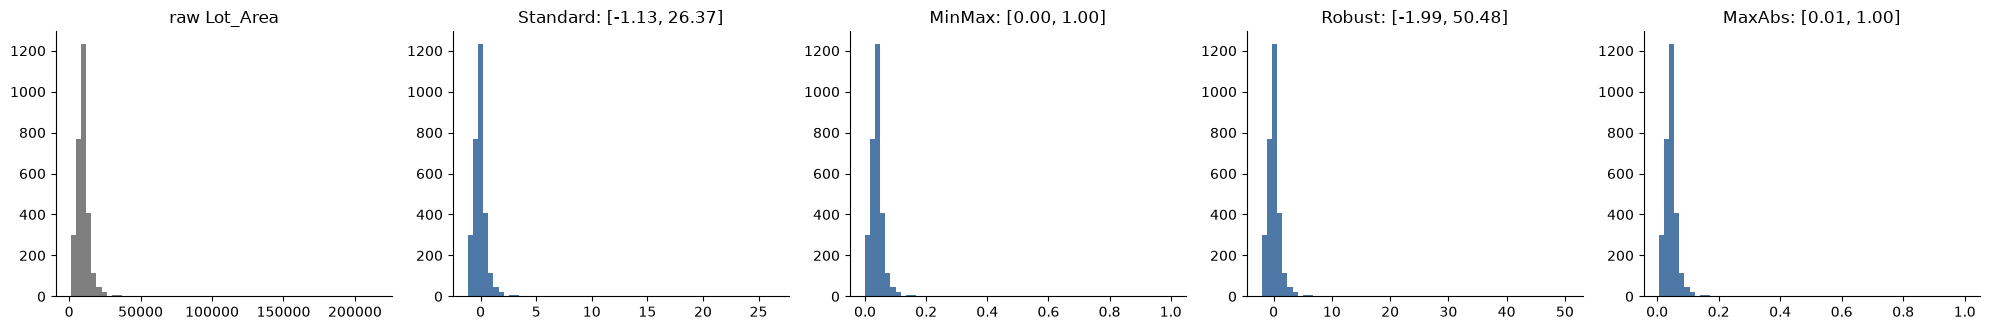

In [2]:
col = "Lot_Area"
scalers = {"Standard": StandardScaler(), "MinMax": MinMaxScaler(), "Robust": RobustScaler(), "MaxAbs": MaxAbsScaler()}
fig, axes = plt.subplots(1, 5, figsize=(20, 3.4))
axes[0].hist(X[col], bins=60, color="#7F7F7F")
axes[0].set_title(f"raw {col}")
for ax, (name, sc) in zip(axes[1:], scalers.items()):
    v = np.asarray(sc.fit_transform(X[[col]])).ravel()
    ax.hist(v, bins=60, color="#4E79A7")
    ax.set_title(f"{name}: [{v.min():.2f}, {v.max():.2f}]")
plt.tight_layout()
plt.show()

Scalers change the **axis**, not the **shape**: the long right tail of `Lot_Area` survives every scaler. With min-max scaling, one huge lot squeezes all other values into a narrow range near 0.

## 2. Transformations for Skewed Features

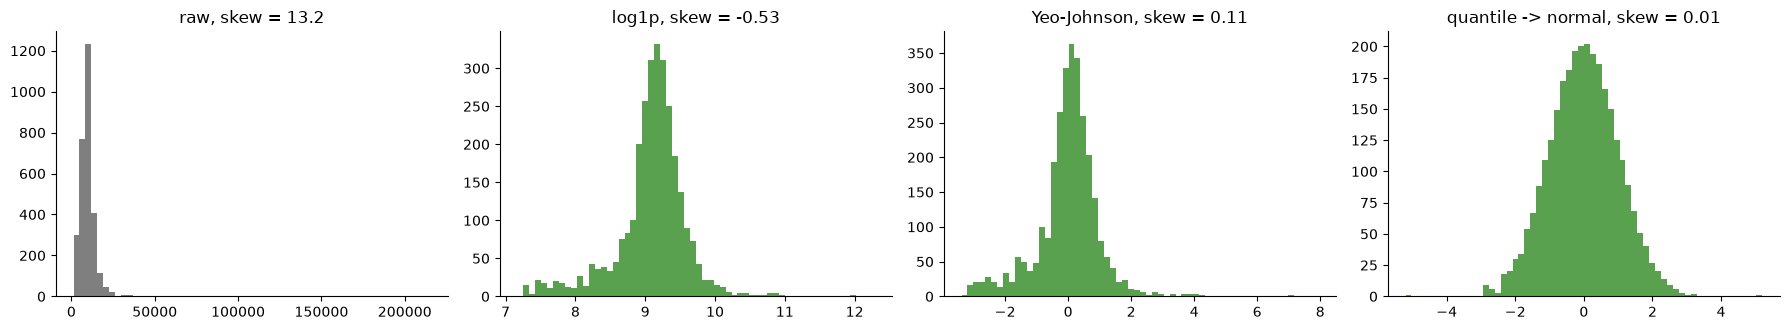

In [3]:
from scipy.stats import skew

transforms = {
    "log1p": FunctionTransformer(np.log1p),
    "Yeo-Johnson": PowerTransformer(method="yeo-johnson"),
    "quantile -> normal": QuantileTransformer(output_distribution="normal", n_quantiles=500, random_state=RNG),
}
fig, axes = plt.subplots(1, 4, figsize=(18, 3.4))
axes[0].hist(X[col], bins=60, color="#7F7F7F")
axes[0].set_title(f"raw, skew = {skew(X[col]):.1f}")
for ax, (name, tf) in zip(axes[1:], transforms.items()):
    v = np.asarray(tf.fit_transform(X[[col]])).ravel()
    ax.hist(v, bins=60, color="#59A14F")
    ax.set_title(f"{name}, skew = {skew(v):.2f}")
plt.tight_layout()
plt.show()

## 3. Which Models Need Scaling? Measure It

The cell compares 5-fold cross-validated errors for three model families with and without scaling.

In [4]:
cv = KFold(5, shuffle=True, random_state=RNG)

def rmse(model):
    return -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()

rows = []
for mname, m in [("k-NN (k=10)", KNeighborsRegressor(10)), ("Ridge (alpha=10)", Ridge(10)),
                 ("Random forest", RandomForestRegressor(200, n_jobs=-1, random_state=RNG))]:
    for sname, sc in [("none", None), ("Standard", StandardScaler()), ("Robust", RobustScaler()), ("MinMax", MinMaxScaler())]:
        model = m if sc is None else make_pipeline(sc, m)
        rows.append({"model": mname, "scaling": sname, "RMSE": rmse(model)})
res = pd.DataFrame(rows).pivot(index="model", columns="scaling", values="RMSE")[["none", "Standard", "Robust", "MinMax"]]
res.round(0)

scaling,none,Standard,Robust,MinMax
model,,,,
Random forest,27714.0,27701.0,27707.0,27712.0
Ridge (alpha=10),36312.0,36314.0,36315.0,37374.0
k-NN (k=10),42755.0,32136.0,33081.0,30964.0


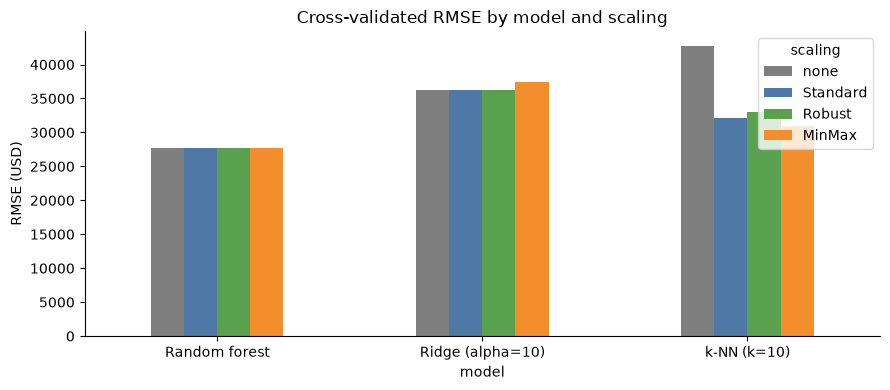

In [5]:
ax = res.plot.bar(figsize=(9, 4), rot=0, color=["#7F7F7F", "#4E79A7", "#59A14F", "#F28E2B"])
ax.set(title="Cross-validated RMSE by model and scaling", ylabel="RMSE (USD)")
plt.tight_layout()
plt.show()

k-NN improves dramatically with scaling: without it, the distance is dominated by the features with the largest numbers (`Lot_Area`). The random forest is unchanged: trees split on thresholds, which do not depend on the scale. Ridge regularisation penalises coefficients, so its result also depends on the scale of the features, although less here.

## 4. Transforming the Target

House prices are right-skewed, and errors grow with price. Modelling $\log(\text{price})$ makes errors relative (percent-like) and often improves linear models. `TransformedTargetRegressor` applies the transform for training and the inverse for predictions, so the evaluation stays in dollars.

In [6]:
base = make_pipeline(StandardScaler(), Ridge(10))
logy = TransformedTargetRegressor(regressor=make_pipeline(PowerTransformer(), Ridge(10)), func=np.log, inverse_func=np.exp)
for name, model in [("Ridge on price", base), ("Ridge on log(price), Yeo-Johnson features", logy)]:
    print(f"{name:<44} RMSE {rmse(model):9,.0f} USD")

Ridge on price                               RMSE    36,314 USD


Ridge on log(price), Yeo-Johnson features    RMSE    31,455 USD


## 5. Fit Scalers on Training Data Only

A scaler learns parameters (mean, std, quantiles). Fitting it on the whole dataset before splitting leaks information from the test set into training (Lesson 09). Put it in a **pipeline**, so that cross-validation fits it on each training fold.

| Model family | Needs scaling? |
| :--- | :--- |
| k-NN, k-means, SVM, PCA | **yes** (distances) |
| linear/logistic regression with regularisation, neural networks | **yes** (penalties, gradients) |
| unregularised linear regression | no for predictions, yes for comparing coefficients |
| decision trees, random forests, gradient boosting | no |

*Insight: Scale features for models that use distances, penalties or gradients, and transform skewed features and targets when the model assumes roughly symmetric errors. Always fit scalers inside a pipeline, and check with cross-validation that the transformation actually helps.*

## Real-World Use Case or Analogy

Scaling is like **converting currencies before comparing prices**: comparing 1,000 yen with 10 euros by the raw numbers is meaningless. A log transform is like talking about **percent changes** instead of absolute changes: a 10,000-dollar difference matters more for a cheap house than for a mansion.

Every production ML system stores its scaler parameters next to the model (for example in a scikit-learn pipeline file), because the same transformation must be applied to new data in exactly the same way.